# Coherence and stellar interferometry

Two points of a light field can interfere only as far as their fields are
correlated. The **complex degree of coherence** $\mu_{12}$ of the fields at
two points (or $\gamma(\tau)$ of the field at two times) says how much: the
fringes that the two make in a Young or Michelson interferometer have the
visibility $|\mu_{12}|$, and their position gives the phase of $\mu_{12}$.
Thermal sources (lamps, LEDs, stars) are incoherent in themselves, yet the
light they send far away is coherent over an area that grows with the
distance and shrinks with the size of the source. That is the
**van Cittert–Zernike theorem**, and it turns a measurement of fringe
visibility against baseline into a measurement of the size of a star.

This notebook builds partial coherence from incoherent sums of coherent
propagations (`propagators.fraunhofer_scaled()`, `fresnel_scaled()`) and
compares it with the analytic results of `coherence`:

1. Young's double pinhole lit by extended sources: the visibility falls
   with the source size like $2J_1(v)/v$ (a disk) or $\mathrm{sinc}$ (a
   slit), and the fringes reverse beyond the first zero,
2. the van Cittert–Zernike theorem by brute force: averages over random
   realizations of an incoherent source against the Fourier transform of
   its intensity, speckle and the coherence area, a double source,
3. Michelson's stellar interferometer on Betelgeuse: fringes in the focal
   plane, visibility against baseline, the first zero at about 3 m, limb
   darkening and binaries, and why the atmosphere washes the fringes out,
4. temporal coherence: Michelson interferograms of an LED, the sodium
   doublet and white light, coherence length against bandwidth for three
   line shapes, and Fourier transform spectroscopy,
5. Hanbury Brown and Twiss: photon bunching of thermal light against a
   laser, $g^{(2)} = 1 + |g^{(1)}|^2$, intensity correlations that measure
   $|\mu_{12}|^2$ without being disturbed by the atmosphere, the price paid
   in signal for slow detectors, and the diameter of Sirius.

The coherence of light in partially coherent *imaging* (Abbe, Hopkins) is
the subject of notebooks 34 and 52.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap
from scipy.integrate import trapezoid
from scipy.optimize import brentq, curve_fit

from pyoptics import coherence
from pyoptics.propagators import fraunhofer_scaled, fresnel_scaled
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")         # magma_r, fading to white at zero
BLUE, RED, GREEN, GREY = "#2a7ab9", "#d6604d", "#5aa469", "0.45"
MAS = np.pi/180/3600e3                      # one milliarcsecond in rad
C_LIGHT = 299792458.0
rng = np.random.default_rng(1234)
t_start = time.time()


def disk_points(diameter, n_r=8, n_phi=24):
    """Points and weights on a uniform disk for incoherent sums.

    Gauss-Legendre in r**2 (equal area) times the midpoint rule in phi: the
    sum of exp(-i k B.alpha) over the points equals 2 J1(v)/v to 1e-6 out to
    the third zero.
    """
    if diameter == 0:
        return np.zeros((1, 2)), np.ones(1)
    q, w = np.polynomial.legendre.leggauss(n_r)
    r = diameter/2*np.sqrt((q + 1)/2)
    phi = (np.arange(n_phi) + 0.5)*2*np.pi/n_phi
    R, PHI = np.meshgrid(r, phi)
    W = np.meshgrid(w/2, phi)[0]/n_phi
    return np.stack([(R*np.cos(PHI)).ravel(), (R*np.sin(PHI)).ravel()], axis=1), W.ravel()


def slit_points(width, n=24):
    """Gauss-Legendre points and weights across a uniform slit along x."""
    if width == 0:
        return np.zeros((1, 2)), np.ones(1)
    q, w = np.polynomial.legendre.leggauss(n)
    return np.stack([q*width/2, np.zeros(n)], axis=1), w/2


def detector_correlation(T, delta_nu=1.0, shape="gaussian"):
    """Intensity correlation of chaotic light (|mu| = 1) averaged over a time T."""
    tau = np.linspace(0, T, 2001)
    return 2/T*trapezoid((1 - tau/T)*coherence.line_coherence(tau, delta_nu, shape)**2, tau)


def extent(x, y=None, scale=1.0):
    y = x if y is None else y
    return [x[0]*scale, x[-1]*scale, y[0]*scale, y[-1]*scale]

## 1. Young's experiment with an extended source

Two pinholes $d = 1$ mm apart are lit by a source in the front focal
plane of a collimator of focal length $f_c = 1$ m, and a lens of focal
length $f = 0.5$ m shows the fringes, with the period $\lambda f/d$. A
point of the source at $(\xi, \eta)$ sends a plane wave tilted by
$(\xi, \eta)/f_c$ onto the pinholes, which makes perfect fringes, shifted
by the phase $k\xi d/f_c$. Points of an incoherent source add their
*intensities*, so their shifted fringe patterns wash each other out. For
each source point the two pinholes are propagated separately with
`fraunhofer_scaled()`; the sum over the source of $|u_1|^2$, $|u_2|^2$ and
$u_1u_2^*$ gives the intensity and the measured degree of coherence

$$I = I_1 + I_2 + 2\sqrt{I_1I_2}\,|\mu_{12}|\cos\left(\frac{2\pi x}{\lambda f/d} - \phi_{12}\right).$$

The van Cittert–Zernike theorem predicts $\mu_{12}$ as the normalized
Fourier transform of the source intensity at the frequency $d/(\lambda f_c)$:
for a uniform disk of diameter $D$

$$\mu_{12} = \frac{2J_1(v)}{v},\qquad v = \frac{\pi D d}{\lambda f_c},$$

which vanishes first at $D = 1.22\,\lambda f_c/d$, and for a uniform slit
of width $s$ across the pinholes $\mu_{12} = \mathrm{sinc}(sd/\lambda f_c)$,
zero at $s = \lambda f_c/d$.

first zero of the disk: D = 0.671 mm, of the slit: s = 0.550 mm


Text(0.5, 0.98, 'double pinhole (d = 1 mm) lit by uniform disks of growing diameter; dashed: I$_1$ + I$_2$')

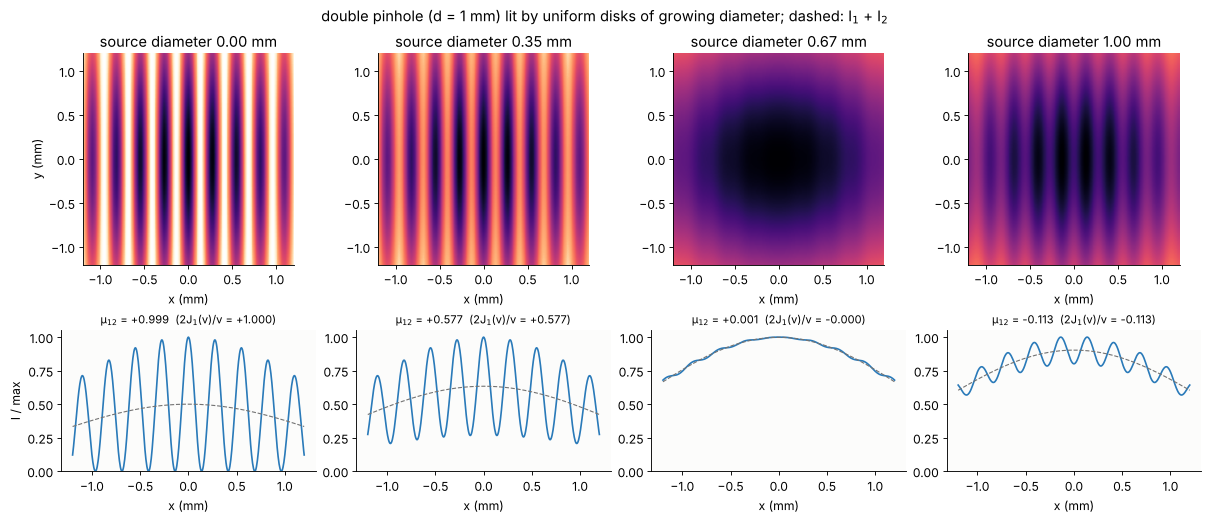

In [2]:
WL = 550e-9
F_C = 1.0                       # collimator: source in its front focal plane
D_PIN = 1e-3                    # pinhole separation
R_PIN = 50e-6                   # pinhole radius
F_SCR = 0.5                     # lens in front of the screen
PERIOD = WL*F_SCR/D_PIN         # fringe period on the screen (0.275 mm)

xp, yp, XP, YP = grid2d(-0.8e-3, 0.8e-3, -0.12e-3, 0.12e-3, 128, 20)
pin1 = ((XP + D_PIN/2)**2 + YP**2 <= R_PIN**2).astype(complex)
pin2 = ((XP - D_PIN/2)**2 + YP**2 <= R_PIN**2).astype(complex)
x_scr = np.linspace(-1.2e-3, 1.2e-3, 481)


def young(source, x_out=x_scr, y_out=np.array([0.0])):
    """Incoherent sum over source points (xi, eta) with weights: I1, I2 and sum u1*conj(u2)."""
    I1 = I2 = S12 = 0
    for (xi, eta), wt in zip(*source):
        tilt = np.exp(-1j*2*np.pi/WL*(xi*XP + eta*YP)/F_C)
        u1, *_ = fraunhofer_scaled(pin1*tilt, xp, yp, F_SCR, WL, x_out, y_out)
        u2, *_ = fraunhofer_scaled(pin2*tilt, xp, yp, F_SCR, WL, x_out, y_out)
        I1, I2, S12 = I1 + wt*abs(u1)**2, I2 + wt*abs(u2)**2, S12 + wt*u1*np.conj(u2)
    return I1, I2, S12


def measured_mu(I1, I2, S12, x=x_scr, half_width=0.7e-3):
    """Signed degree of coherence from a fit of the normalized cross term."""
    sel = np.abs(x) < half_width
    cross = (2*S12.real/(2*np.sqrt(I1*I2)))[0, sel]       # |mu| cos(2 pi x/p - phi)
    V, phi = coherence.fit_fringes(x[sel], 1 + cross, PERIOD)
    return V*np.cos(phi), phi


D0 = 1.22*WL*F_C/D_PIN
print("first zero of the disk: D = {:.3f} mm, of the slit: s = {:.3f} mm".format(D0*1e3, WL*F_C/D_PIN*1e3))
D_show = [0.0, 0.35e-3, D0, 1.0e-3]
x_img = np.linspace(-1.2e-3, 1.2e-3, 161)
fig, ax = plt.subplots(2, 4, figsize=(15, 6.4), layout="constrained",
                       gridspec_kw={"height_ratios": [1.5, 1]})
for i, D in enumerate(D_show):
    pts = disk_points(D)
    I1, I2, S12 = young(pts, x_img, x_img)
    I = I1 + I2 + 2*S12.real
    ax[0, i].imshow(I/I.max(), extent=extent(x_img, scale=1e3), cmap=LIGHT, vmin=0, vmax=1)
    ax[0, i].set_title("source diameter {:.2f} mm".format(D*1e3))
    ax[0, i].set_xlabel("x (mm)")
    I1, I2, S12 = young(pts)
    I = (I1 + I2 + 2*S12.real)[0]
    mu, _ = measured_mu(I1, I2, S12)
    ax[1, i].plot(x_scr*1e3, I/I.max(), color=BLUE)
    ax[1, i].plot(x_scr*1e3, (I1 + I2)[0]/I.max(), color=GREY, ls="--", lw=1)
    ax[1, i].set_title("μ$_{12}$ = %+.3f  (2J$_1$(v)/v = %+.3f)"
                       % (mu, coherence.uniform_disk_visibility(D_PIN, D/F_C, WL)), fontsize=10)
    ax[1, i].set_xlabel("x (mm)")
    ax[1, i].set_ylim(0, 1.05)
ax[0, 0].set_ylabel("y (mm)")
ax[1, 0].set_ylabel("I / max")
fig.suptitle("double pinhole (d = 1 mm) lit by uniform disks of growing diameter; dashed: I$_1$ + I$_2$")

At the first zero ($D = 0.67$ mm) the fringes are gone, although each
point of the source alone would make perfect fringes. Beyond it they come
back with a lower contrast and *reversed*: a bright fringe sits where the
centre of the pattern was dark. $\mu_{12}$ is negative there, and the fit
finds the fringe phase $\phi_{12} = \pi$. The sweep below fits the
visibility for many disks and slits.

largest deviation from the analytic mu: disk 1.2e-03, slit 2.6e-03


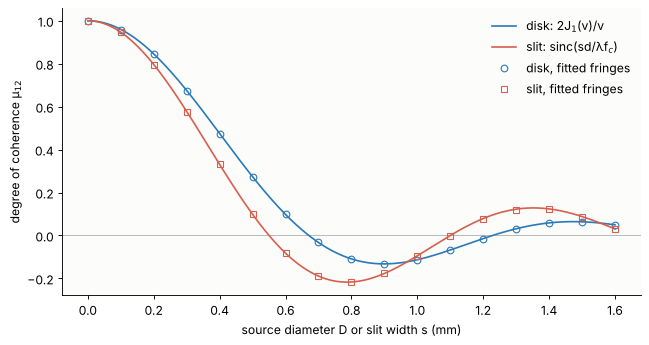

In [3]:
D_sweep = np.linspace(0, 1.6e-3, 17)
s_sweep = np.linspace(0, 1.6e-3, 17)
mu_disk = np.array([measured_mu(*young(disk_points(D)))[0] for D in D_sweep])
mu_slit = np.array([measured_mu(*young(slit_points(s)))[0] for s in s_sweep])

size = np.linspace(0, 1.6e-3, 400)
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.axhline(0, color="0.7", lw=0.8)
ax.plot(size*1e3, coherence.uniform_disk_visibility(D_PIN, size/F_C, WL), color=BLUE,
        label="disk: 2J$_1$(v)/v")
ax.plot(size*1e3, np.sinc(size*D_PIN/(WL*F_C)), color=RED, label="slit: sinc(sd/λf$_c$)")
ax.plot(D_sweep*1e3, mu_disk, "o", color=BLUE, mfc="none", label="disk, fitted fringes")
ax.plot(s_sweep*1e3, mu_slit, "s", color=RED, mfc="none", label="slit, fitted fringes")
ax.set_xlabel("source diameter D or slit width s (mm)")
ax.set_ylabel("degree of coherence μ$_{12}$")
ax.legend(frameon=False)
print("largest deviation from the analytic mu: disk {:.1e}, slit {:.1e}".format(
    np.max(np.abs(mu_disk - coherence.uniform_disk_visibility(D_PIN, D_sweep/F_C, WL))),
    np.max(np.abs(mu_slit - np.sinc(s_sweep*D_PIN/(WL*F_C))))))

The fitted visibilities follow the van Cittert–Zernike prediction to a
few $10^{-3}$; the rest comes from the pinholes, whose finite size
(0.1 mm against $d = 1$ mm) averages $\mu$ over their area. The
slit, whose intensity projected onto the baseline is a rectangle, loses its
fringes at a smaller width than the disk of the same diameter, whose
projection is a half-ellipse with less weight at the edges. The same
experiment read backwards measures the source: increase $d$ until the
fringes vanish, and $D = 1.22\,\lambda f_c/d$.

## 2. The van Cittert–Zernike theorem by brute force

An incoherent source has fields that are uncorrelated from point to
point: $\langle u(\boldsymbol\xi_1)u^*(\boldsymbol\xi_2)\rangle =
I(\boldsymbol\xi_1)\,\delta(\boldsymbol\xi_1 - \boldsymbol\xi_2)$.
A *realization* of such a source, with a random complex Gaussian amplitude
of variance $I$ in each sample (`coherence.incoherent_source_realization()`),
is propagated with `fresnel_scaled()` a distance $z$ to an observation plane
where it is a speckle pattern. Averaging $u(\mathbf r)u^*(0)$ over many
realizations gives the mutual intensity and with it $\mu(\mathbf r, 0)$. The
theorem says that

$$\mu(\mathbf r_1, \mathbf r_2) = e^{i\psi}\,
  \frac{\int I(\boldsymbol\xi)\,e^{-ik(\mathbf r_1 - \mathbf r_2)\cdot\boldsymbol\xi/z}\,d^2\xi}{\int I\,d^2\xi},
  \qquad \psi = \frac{k\,(r_1^2 - r_2^2)}{2z},$$

the Fourier transform of the source intensity, like the far field of a
coherent aperture of the same shape. `coherence.mutual_intensity_vcz()`
evaluates it for any source with chirp-z transforms. A disk of radius $a$
gives $|\mu| = |2J_1(v)/v|$ with $v = 2\pi a r/(\lambda z)$, and the
*coherence area* $\approx \lambda^2 z^2/(\pi a^2)$, the size of a speckle.

Two sources: a disk of 0.2 mm diameter and a double source (two small
disks 0.2 mm apart, one half as bright), both 1 m from the observation plane.

2 x 2000 propagations in 11.5 s


disk           rms |mu_real - mu_VCZ| = 0.022 (statistical error ~ 1/sqrt(N) = 0.022)
double source  rms |mu_real - mu_VCZ| = 0.017 (statistical error ~ 1/sqrt(N) = 0.022)
first zero of the disk's mu at r = 0.61 lambda z/a = 3.05 mm


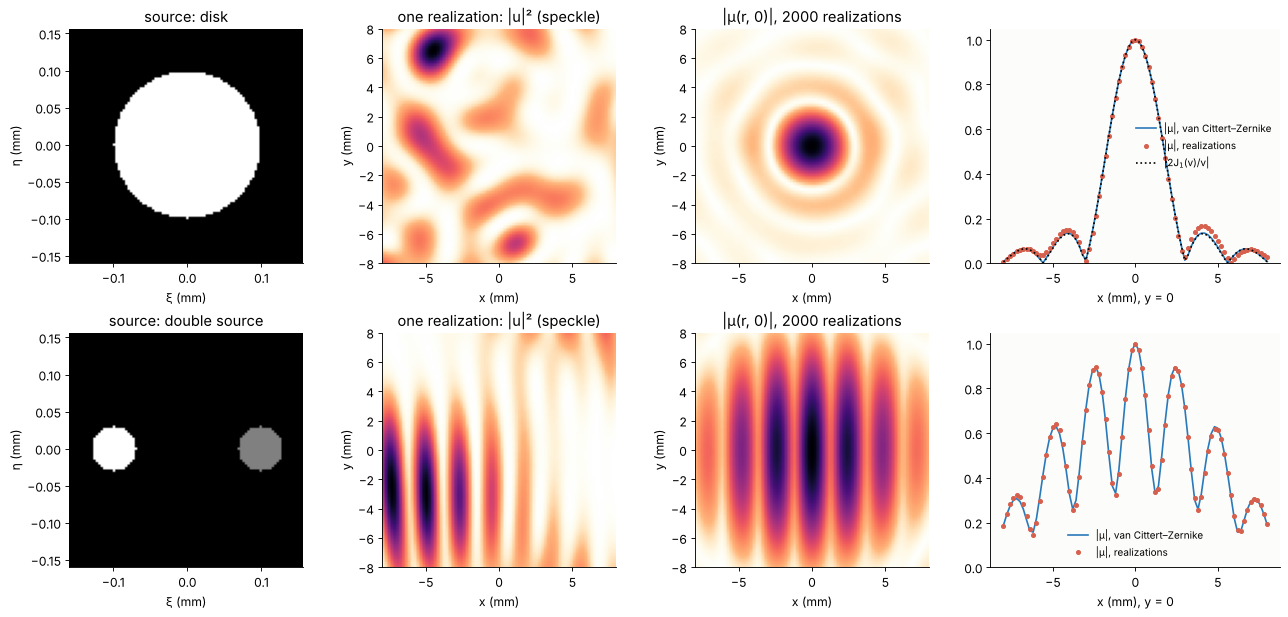

In [4]:
WL2, Z2, A2 = 500e-9, 1.0, 0.1e-3
xs, ys, XS, YS = grid2d(-0.16e-3, 0.16e-3, -0.16e-3, 0.16e-3, 96)
src_disk = (XS**2 + YS**2 <= A2**2).astype(float)
src_double = (((XS + 0.1e-3)**2 + YS**2 <= 0.03e-3**2) + 0.5*((XS - 0.1e-3)**2 + YS**2 <= 0.03e-3**2))
x_obs = np.linspace(-8e-3, 8e-3, 81)          # x_obs[40] = 0
N_REAL = 2000


def realizations(src):
    """Speckle fields of N_REAL incoherent realizations, at distance Z2."""
    return np.array([fresnel_scaled(coherence.incoherent_source_realization(src, rng, gaussian=True),
                                    xs, ys, Z2, WL2, x_obs, x_obs)[0] for _ in range(N_REAL)])


t0 = time.time()
U_disk = realizations(src_disk)
U_double = realizations(src_double)
print("2 x {} propagations in {:.1f} s".format(N_REAL, time.time() - t0))
psi = np.pi*(x_obs[None, :]**2 + x_obs[:, None]**2)/(WL2*Z2)     # k r^2/(2z), r2 = 0


def mu_from_realizations(U):
    J = np.mean(U*np.conj(U[:, 40, 40])[:, None, None], axis=0)
    I = np.mean(np.abs(U)**2, axis=0)
    return J/np.sqrt(I*I[40, 40])*np.exp(-1j*psi)            # reduced degree of coherence


fig, ax = plt.subplots(2, 4, figsize=(16, 7.6), layout="constrained")
for row, (src, U, name) in enumerate([(src_disk, U_disk, "disk"), (src_double, U_double, "double source")]):
    mu_r = mu_from_realizations(U)
    mu_v = coherence.mutual_intensity_vcz(src, xs, ys, WL2, x_obs, x_obs, z=Z2)
    ax[row, 0].imshow(src, extent=extent(xs, scale=1e3), cmap="gray")
    ax[row, 0].set_title("source: " + name)
    ax[row, 0].set_xlabel("ξ (mm)"); ax[row, 0].set_ylabel("η (mm)")
    ax[row, 1].imshow(np.abs(U[0])**2, extent=extent(x_obs, scale=1e3), cmap=LIGHT)
    ax[row, 1].set_title("one realization: |u|² (speckle)")
    ax[row, 2].imshow(np.abs(mu_r), extent=extent(x_obs, scale=1e3), cmap=LIGHT, vmin=0, vmax=1)
    ax[row, 2].set_title("|μ(r, 0)|, {} realizations".format(N_REAL))
    for a in ax[row, 1:3]:
        a.set_xlabel("x (mm)"); a.set_ylabel("y (mm)")
    ax[row, 3].plot(x_obs*1e3, np.abs(mu_v[40]), color=BLUE, label="|μ|, van Cittert–Zernike")
    ax[row, 3].plot(x_obs*1e3, np.abs(mu_r[40]), "o", ms=3.5, color=RED, label="|μ|, realizations")
    if row == 0:
        ax[row, 3].plot(x_obs*1e3, np.abs(coherence.uniform_disk_visibility(x_obs, 2*A2/Z2, WL2)), ":",
                        color="k", label="|2J$_1$(v)/v|")
    ax[row, 3].set_xlabel("x (mm), y = 0"); ax[row, 3].set_ylim(0, 1.05)
    ax[row, 3].legend(frameon=False, fontsize=9)
    print("{:14s} rms |mu_real - mu_VCZ| = {:.3f} (statistical error ~ 1/sqrt(N) = {:.3f})".format(
        name, np.sqrt(np.mean(np.abs(mu_r - mu_v)**2)), 1/np.sqrt(N_REAL)))
r0 = 0.61*WL2*Z2/A2
print("first zero of the disk's mu at r = 0.61 lambda z/a = {:.2f} mm".format(r0*1e3))

The averaged realizations agree with the Fourier transform of the source
intensity within their statistical error $\sim 1/\sqrt N$. The speckle
grains of a single realization have the size of the coherence area:
within a grain the field is the same in every realization, up to a common
random factor. The double source gives $|\mu|$ that oscillates with the
period $\lambda z/0.2\,\mathrm{mm} = 2.5$ mm between $1$ and
$(1 - 0.5)/(1 + 0.5) = 1/3$, under the envelope of the small disks: the
fringes of a *binary star*.

Note the phase factor $e^{i\psi}$: the unreduced $\mu$ has the quadratic
phase of a spherical wave from the source's centre. It does not change the
visibility, but it does shift the fringes of a Young experiment set up
off-axis.

## 3. Michelson's stellar interferometer: the diameter of Betelgeuse

For a star the source is at infinity and the theorem is written with
angles: $\mu(\mathbf B) = \int I(\boldsymbol\alpha)e^{-ik\mathbf B\cdot
\boldsymbol\alpha}d^2\alpha/\int I$ for two points a baseline $\mathbf B$
apart. A uniform stellar disk of angular diameter $\theta$ gives
$2J_1(v)/v$, $v = \pi\theta B/\lambda$, with the first zero at
$B_0 = 1.22\lambda/\theta$. For $\theta = 0.05''$ that is about 3 m, more
than the diameter of any telescope of 1920. Michelson's trick: two
periscope mirrors a baseline $B$ apart pick up the starlight, and two inner
mirrors a fixed distance $h$ apart send it into the telescope. The fringe
*period* in the focal plane, $\lambda f/h$, is set by $h$; the fringe
*visibility* by $B$, because the phase between the beams for a star at
angle $\alpha$ is $k\alpha B$.

In December 1920 Michelson and Pease saw the fringes of Betelgeuse
($\alpha$ Orionis) vanish at $B = 121$ inches $= 3.07$ m. With the
effective wavelength 575 nm this gives a uniform disk of
$\theta = 1.22\lambda/B_0 = 0.047''$, the first measured diameter of a star
other than the Sun. Below, a disk of 47 mas is the star, the two beams
(15 cm) are $h = 1.14$ m apart, and the telescope has $f = 40$ m.

In [5]:
WL_S = 575e-9
THETA_BET = 47*MAS
H_IN = 1.14                     # inner mirror separation
D_BEAM = 0.15
F_TEL = 40.0
P_TEL = WL_S*F_TEL/H_IN        # fringe period in the focal plane (20 um)

xt, yt, XT, YT = grid2d(-0.66, 0.66, -0.1, 0.1, 264, 40)
beam1 = ((XT + H_IN/2)**2 + YT**2 <= (D_BEAM/2)**2).astype(complex)
beam2 = ((XT - H_IN/2)**2 + YT**2 <= (D_BEAM/2)**2).astype(complex)
x_foc = np.linspace(-150e-6, 150e-6, 601)
star_points = disk_points(THETA_BET)
print("{} points on the stellar disk, fringe period {:.1f} um, Airy radius of a beam {:.0f} um".format(
    len(star_points[0]), P_TEL*1e6, 1.22*WL_S*F_TEL/D_BEAM*1e6))
print("first zero for a uniform disk of 47 mas: B0 = {:.3f} m".format(
    coherence.uniform_disk_first_zero(THETA_BET, WL_S)))


def stellar(B, points=star_points, x_out=x_foc, y_out=np.array([0.0])):
    """Focal plane of the stellar interferometer: I1, I2 and sum u1*conj(u2)."""
    I1 = I2 = S12 = 0
    k = 2*np.pi/WL_S
    for (a, b), wt in zip(*points):
        tilt = np.exp(1j*k*(a*XT + b*YT))
        # the periscopes translate the beams from x = -+B/2 to x = -+h/2: the
        # tilt across each beam stays, the piston is that of the outer mirror
        u1, *_ = fraunhofer_scaled(beam1*tilt*np.exp(1j*k*a*(-B/2 + H_IN/2)), xt, yt, F_TEL, WL_S, x_out, y_out)
        u2, *_ = fraunhofer_scaled(beam2*tilt*np.exp(1j*k*a*(B/2 - H_IN/2)), xt, yt, F_TEL, WL_S, x_out, y_out)
        I1, I2, S12 = I1 + wt*abs(u1)**2, I2 + wt*abs(u2)**2, S12 + wt*u1*np.conj(u2)
    return I1, I2, S12


def stellar_mu(I1, I2, S12, half_width=60e-6):
    sel = np.abs(x_foc) < half_width
    cross = (S12.real/np.sqrt(I1*I2))[0, sel]
    V, phi = coherence.fit_fringes(x_foc[sel], 1 + cross, P_TEL)
    return V*np.cos(phi)

192 points on the stellar disk, fringe period 20.2 um, Airy radius of a beam 187 um
first zero for a uniform disk of 47 mas: B0 = 3.078 m


Text(0, 0.5, 'y (μm)')

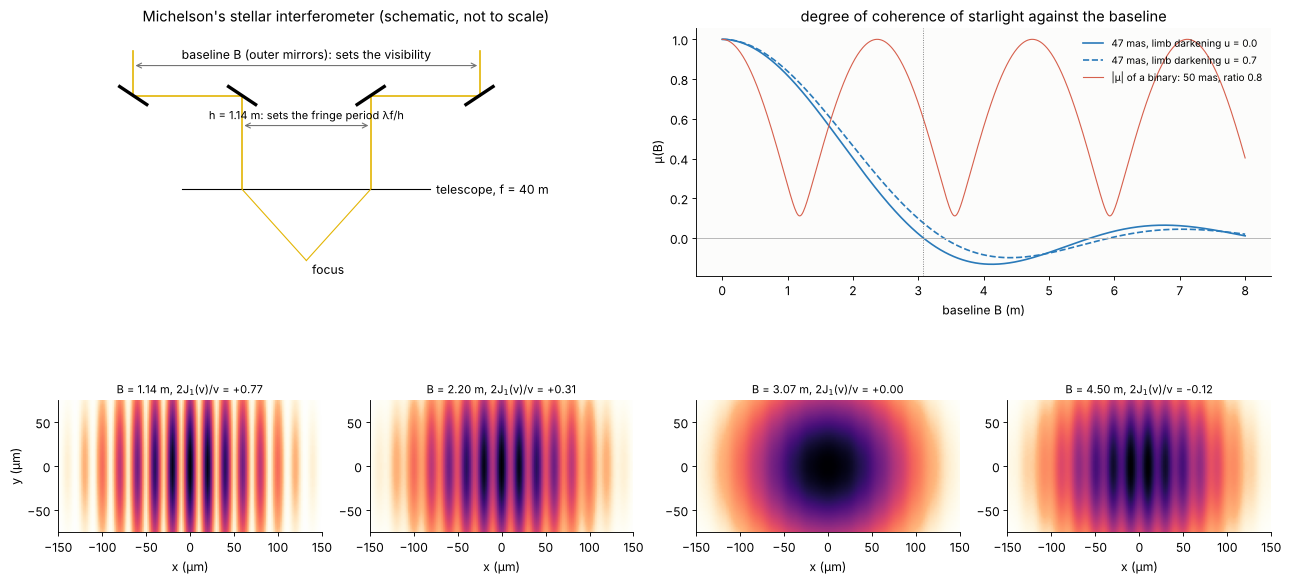

In [6]:
# sketch of the interferometer and focal plane images for four baselines
fig = plt.figure(figsize=(16, 7.6), layout="constrained")
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1.15])
ax = fig.add_subplot(gs[0, :2])
B_sk = 3.07
for s in (-1, 1):
    ax.plot([s*B_sk/2]*2, [2.2, 1.6], color="#e3b505", lw=1.5)                 # starlight
    ax.plot([s*B_sk/2, s*H_IN/2], [1.6, 1.6], color="#e3b505", lw=1.5)
    ax.plot([s*H_IN/2]*2, [1.6, 0.35], color="#e3b505", lw=1.5)
    for xm in (s*B_sk/2, s*H_IN/2):                    # 45 deg mirrors, parallel on each side
        ax.plot([xm - 0.12, xm + 0.12], [1.6 - 0.12*s, 1.6 + 0.12*s], color="k", lw=3)
ax.plot([-1.1, 1.1], [0.35, 0.35], color="k", lw=1)
ax.plot([-H_IN/2, 0], [0.35, -0.6], color="#e3b505", lw=1); ax.plot([H_IN/2, 0], [0.35, -0.6], color="#e3b505", lw=1)
ax.annotate("", (-B_sk/2, 2.0), (B_sk/2, 2.0), arrowprops=dict(arrowstyle="<->", color=GREY))
ax.text(0, 2.05, "baseline B (outer mirrors): sets the visibility", ha="center", va="bottom")
ax.annotate("", (-H_IN/2, 1.2), (H_IN/2, 1.2), arrowprops=dict(arrowstyle="<->", color=GREY))
ax.text(0, 1.25, "h = 1.14 m: sets the fringe period λf/h", ha="center", va="bottom", fontsize=10)
ax.text(1.15, 0.35, "telescope, f = 40 m", va="center")
ax.text(0.05, -0.62, "focus", va="top")
ax.set_xlim(-2.2, 2.9); ax.set_ylim(-0.8, 2.5); ax.axis("off")
ax.set_title("Michelson's stellar interferometer (schematic, not to scale)")

ax = fig.add_subplot(gs[0, 2:])
B_curve = np.linspace(0, 8, 600)
for u_ld, ls in [(0.0, "-"), (0.7, "--")]:
    ax.plot(B_curve, coherence.limb_darkened_disk_visibility(B_curve, THETA_BET, WL_S, u_ld),
            color=BLUE, ls=ls, label="47 mas, limb darkening u = {}".format(u_ld))
ax.plot(B_curve, np.abs(coherence.binary_visibility(B_curve, 50*MAS, 0.8, WL_S)), color=RED, lw=1,
        label="|μ| of a binary: 50 mas, ratio 0.8")
ax.axhline(0, color="0.7", lw=0.8); ax.axvline(3.07, color=GREY, lw=0.8, ls=":")
ax.set_xlabel("baseline B (m)"); ax.set_ylabel("μ(B)")
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.set_title("degree of coherence of starlight against the baseline")

x_img2 = np.linspace(-150e-6, 150e-6, 151)
y_img2 = np.linspace(-75e-6, 75e-6, 76)
for i, B in enumerate([H_IN, 2.2, 3.07, 4.5]):
    I1, I2, S12 = stellar(B, x_out=x_img2, y_out=y_img2)
    I = I1 + I2 + 2*S12.real
    a = fig.add_subplot(gs[1, i])
    a.imshow(I/I.max(), extent=extent(x_img2, y_img2, 1e6), cmap=LIGHT, vmin=0, vmax=1)
    a.set_title("B = {:.2f} m, 2J$_1$(v)/v = {:+.2f}".format(
        B, coherence.uniform_disk_visibility(B, THETA_BET, WL_S)), fontsize=10)
    a.set_xlabel("x (μm)")
fig.axes[2].set_ylabel("y (μm)")

With the outer mirrors as close as the inner ones ($B = h$) the star is
hardly resolved and the fringes are almost perfect. At 3.07 m they vanish,
beyond that they return with reversed phase and low contrast. The fit
over the sweep of baselines below recovers $2J_1(v)/v$.

**Limb darkening.** A real star is darker at the limb, with a brightness
$1 - u(1 - \cos\vartheta)$, where $\vartheta$ is the angle from the normal
to its surface. Its visibility (`coherence.limb_darkened_disk_visibility()`)
has its first zero at a longer baseline than the uniform disk of the same
diameter. A uniform disk fitted to the first zero therefore underestimates
the true diameter. Modern measurements of Betelgeuse give a limb darkened
diameter of about 42 to 45 mas in the near infrared (the star is also
variable and spotted).

largest deviation from 2J1(v)/v: 5.6e-04
diameter from the first zero at 3.07 m: 47.1 mas


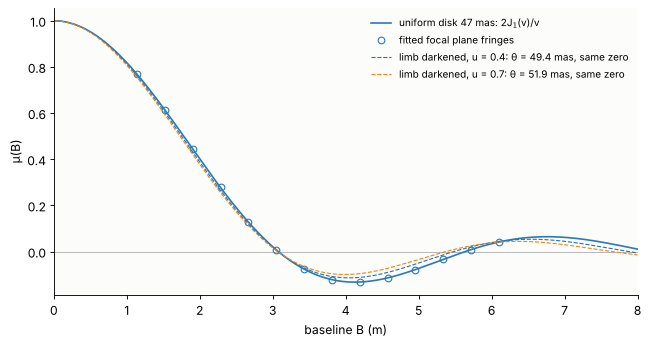

In [7]:
B_sweep = np.linspace(H_IN, 6.1, 14)          # Michelson's 20 ft beam allowed up to 6.1 m
mu_meas = np.array([stellar_mu(*stellar(B)) for B in B_sweep])
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.axhline(0, color="0.7", lw=0.8)
ax.plot(B_curve, coherence.uniform_disk_visibility(B_curve, THETA_BET, WL_S), color=BLUE,
        label="uniform disk 47 mas: 2J$_1$(v)/v")
ax.plot(B_sweep, mu_meas, "o", color=BLUE, mfc="none", label="fitted focal plane fringes")
for u_ld in (0.4, 0.7):
    zero = brentq(lambda th: coherence.limb_darkened_disk_visibility(3.07, th, WL_S, u_ld), 30*MAS, 70*MAS)
    ax.plot(B_curve, coherence.limb_darkened_disk_visibility(B_curve, zero, WL_S, u_ld), ls="--", lw=1,
            label="limb darkened, u = {}: θ = {:.1f} mas, same zero".format(u_ld, zero/MAS))
ax.set_xlim(0, 8); ax.set_xlabel("baseline B (m)"); ax.set_ylabel("μ(B)")
ax.legend(frameon=False, fontsize=9)
print("largest deviation from 2J1(v)/v: {:.1e}".format(
    np.max(np.abs(mu_meas - coherence.uniform_disk_visibility(B_sweep, THETA_BET, WL_S)))))
print("diameter from the first zero at 3.07 m: {:.1f} mas".format(1.2197*WL_S/3.07/MAS))

**Why the atmosphere is the enemy.** Turbulence above each mirror adds a
random optical path, and the *difference* between the two arms shifts the
fringes by the phase $\delta$. The fringes stay sharp in a short exposure
but dance; in a long one they average out to the visibility
$|\mu|\,|\langle e^{i\delta}\rangle| = |\mu|\,e^{-\sigma^2/2}$ for Gaussian
phases of rms $\sigma$. Path fluctuations of a micron ($\sigma \approx
11$ rad) leave nothing. Michelson and Pease watched the fringes by eye,
which integrates over a few tens of ms, and the path difference had to be
kept within the coherence length of the light (section 4), about a
micron for unfiltered starlight. The baseline could not be stretched far
beyond 6 m, and amplitude interferometry stalled for decades. The piston
acts on $u_1u_2^*$ only, so the patterns of a frame are
$I_1 + I_2 + 2\,\mathrm{Re}(S_{12}e^{i\delta})$.

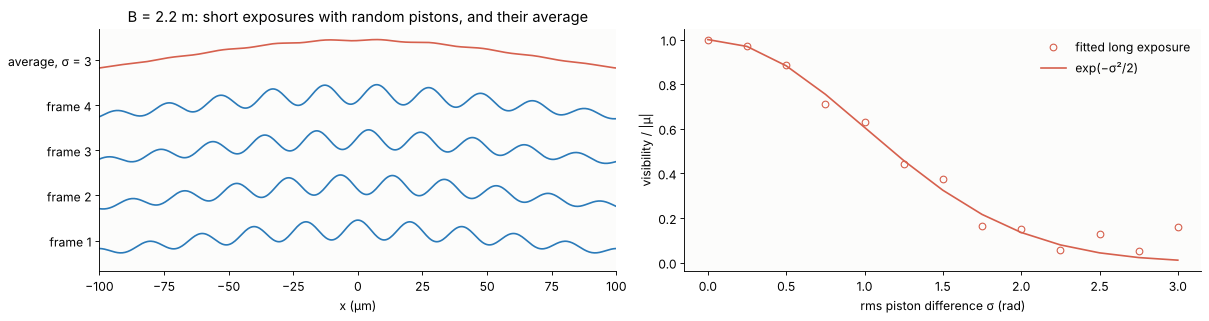

In [8]:
I1, I2, S12 = stellar(2.2)
sigmas = np.linspace(0, 3, 13)
n_frames = 400
V_long = []
for sigma in sigmas:
    deltas = sigma*rng.standard_normal(n_frames)
    I_long = np.mean([I1 + I2 + 2*(S12*np.exp(1j*d)).real for d in deltas], axis=0)
    sel = np.abs(x_foc) < 60e-6
    V_long.append(coherence.fit_fringes(x_foc[sel], ((I_long - I1 - I2)/(2*np.sqrt(I1*I2)) + 1)[0, sel],
                                        P_TEL)[0])
V0 = abs(stellar_mu(I1, I2, S12))

fig, ax = plt.subplots(1, 2, figsize=(15, 3.9), layout="constrained")
for j, d in enumerate([0.0, 2.1, -1.3, 4.0]):
    I = (I1 + I2 + 2*(S12*np.exp(1j*d)).real)[0]
    ax[0].plot(x_foc*1e6, I/I.max() + 1.1*j, color=BLUE)
I = (I1 + I2 + 2*(S12*np.exp(1j*sigma*rng.standard_normal((n_frames, 1, 1)))).real).mean(0)[0]
ax[0].plot(x_foc*1e6, I/I.max() + 4.4, color=RED)
ax[0].set_yticks([0.5 + 1.1*j for j in range(5)], ["frame 1", "frame 2", "frame 3", "frame 4",
                                                    "average, σ = 3"])
ax[0].set_xlabel("x (μm)"); ax[0].set_xlim(-100, 100)
ax[0].set_title("B = 2.2 m: short exposures with random pistons, and their average")
ax[1].plot(sigmas, np.array(V_long)/V0, "o", color=RED, mfc="none", label="fitted long exposure")
ax[1].plot(sigmas, np.exp(-sigmas**2/2), color=RED, label="exp(−σ²/2)")
ax[1].set_xlabel("rms piston difference σ (rad)"); ax[1].set_ylabel("visibility / |μ|")
ax[1].legend(frameon=False)

## 4. Temporal coherence: visibility against path difference

A Michelson interferometer splits a beam and recombines it with the
optical path difference $\Delta = c\tau$. Each frequency makes its own
fringes $1 + \cos(2\pi\nu\Delta/c)$, and the frequencies of a thermal
source are mutually incoherent, so their intensities add up:

$$I(\Delta) \propto \int S(\nu)\left[1 + \cos\frac{2\pi\nu\Delta}{c}\right]d\nu
  = 1 + \mathrm{Re}\,\gamma(\Delta/c),\qquad
  \gamma(\tau) = \frac{\int S(\nu)e^{-2\pi i\nu\tau}d\nu}{\int S\,d\nu}.$$

The visibility at the path difference $\Delta$ is the envelope
$|\gamma(\Delta/c)|$ of the Fourier transform of the spectrum
(Wiener–Khinchin, `coherence.degree_of_coherence()`). Below, the
interferograms are summed over the spectral lines frequency by frequency,
and the visibility fitted in short windows (`coherence.fit_fringes()`)
is compared with $|\gamma|$:

- a red LED, 630 nm with a Gaussian line of 20 nm FWHM,
  $|\gamma| = \exp(-(\pi\Delta\nu\tau)^2/4\ln 2)$,
- the sodium D doublet, 589.0 and 589.6 nm (2:1), whose two lines beat with
  the period $\lambda^2/\delta\lambda = 0.58$ mm in path difference,
- white light, flat from 400 to 700 nm in wavelength: a few fringes around
  zero path difference, where all colours are in phase.

Text(0.5, 0, 'optical path difference Δ (μm)')

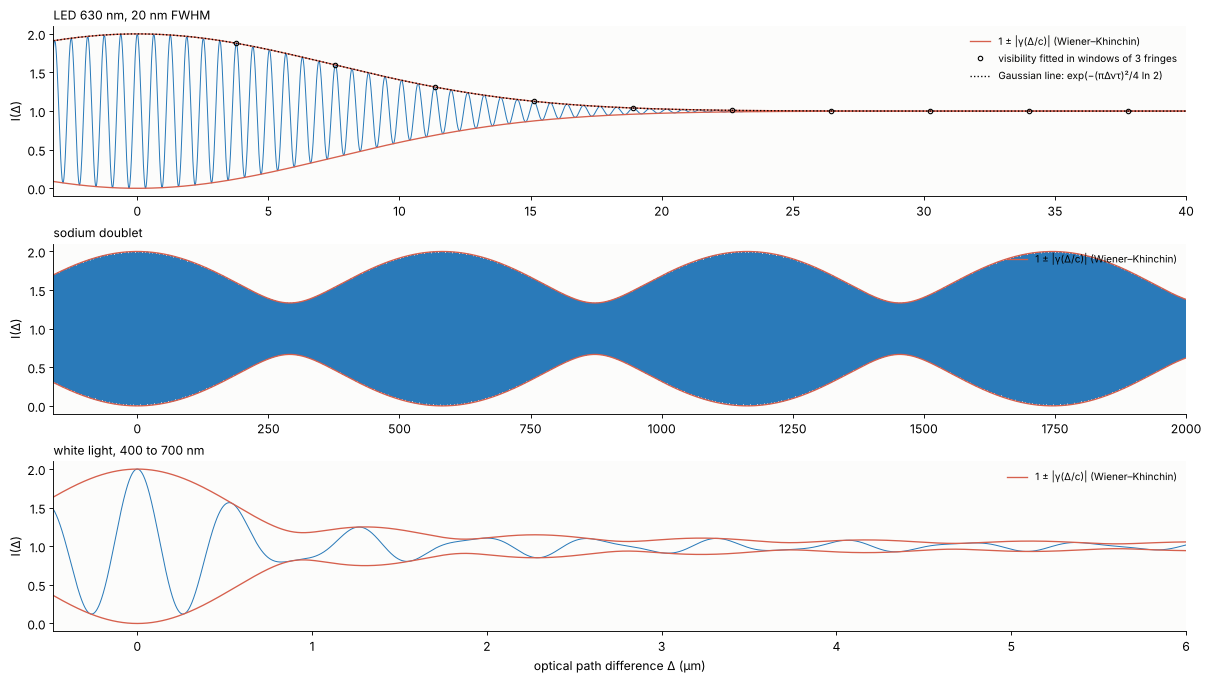

In [9]:
def michelson(opd, nu, weights, chunk=1000):
    """Interferogram sum_nu w(nu)*(1 + cos(2 pi nu opd/c))/sum w, in chunks of path differences."""
    out = np.empty(len(opd))
    for i in range(0, len(opd), chunk):
        out[i:i + chunk] = (1 + np.cos(2*np.pi*np.multiply.outer(opd[i:i + chunk], nu)/C_LIGHT)) @ weights
    return out/np.sum(weights)


def gaussian_lines(lam, centres, widths, weights):
    """Sum of Gaussian lines in wavelength, as a spectrum over frequency (same samples)."""
    S = 0
    for c, w, a in zip(centres, widths, weights):
        S = S + a*np.exp(-4*np.log(2)*((lam - c)/w)**2)
    return S


lam_led = np.linspace(560e-9, 700e-9, 3000)
lam_na = np.linspace(588.6e-9, 590.0e-9, 3000)
lam_white = np.linspace(380e-9, 720e-9, 6000)
sources = {
    "LED 630 nm, 20 nm FWHM": (lam_led, gaussian_lines(lam_led, [630e-9], [20e-9], [1]), 40e-6),
    "sodium doublet": (lam_na, gaussian_lines(lam_na, [588.995e-9, 589.592e-9], [0.002e-9]*2, [2, 1]), 2.0e-3),
    "white light, 400 to 700 nm": (lam_white, ((lam_white > 400e-9) & (lam_white < 700e-9)).astype(float), 6e-6),
}

fig, ax = plt.subplots(3, 1, figsize=(15, 8.4), layout="constrained")
for a, (name, (lam, S_lam, opd_max)) in zip(ax, sources.items()):
    keep = S_lam > 1e-9*S_lam.max()
    lam, S_lam = lam[keep], S_lam[keep]
    nu = C_LIGHT/lam
    w = S_lam*lam**2/C_LIGHT*np.abs(np.gradient(nu))   # S(nu) dnu = S(lambda) dlambda
    opd = np.linspace(-opd_max*0.08, opd_max, 6001 if opd_max < 1e-3 else 40001)
    I = michelson(opd, nu, w)
    nu_mean = np.sum(nu*w)/np.sum(w)
    env = np.concatenate([np.abs(coherence.degree_of_coherence(nu - nu_mean, w, opd[i:i + 2000]/C_LIGHT))
                          for i in range(0, len(opd), 2000)])
    a.plot(opd*1e6, I, color=BLUE, lw=0.5 if opd_max > 1e-3 else 0.9)
    a.plot(opd*1e6, 1 + env, color=RED, lw=1.2, label="1 ± |γ(Δ/c)| (Wiener–Khinchin)")
    a.plot(opd*1e6, 1 - env, color=RED, lw=1.2)
    if name.startswith("LED"):
        p = C_LIGHT/nu_mean
        centres = np.arange(0, opd_max, 6*p)[1:]
        V_fit = [coherence.fit_fringes(opd[np.abs(opd - c) < 1.5*p], I[np.abs(opd - c) < 1.5*p], p)[0]
                 for c in centres]
        dnu = C_LIGHT*20e-9/630e-9**2
        a.plot(centres*1e6, 1 + np.array(V_fit), "o", ms=4, color="k", mfc="none",
               label="visibility fitted in windows of 3 fringes")
        a.plot(opd*1e6, 1 + coherence.line_coherence(opd/C_LIGHT, dnu), ":", color="k", lw=1.2,
               label="Gaussian line: exp(−(πΔντ)²/4 ln 2)")
    a.set_title(name, fontsize=11, loc="left")
    a.set_ylabel("I(Δ)")
    a.set_xlim(opd[0]*1e6, opd[-1]*1e6)
    a.legend(frameon=False, fontsize=9, loc="upper right", framealpha=0.9)
ax[-1].set_xlabel("optical path difference Δ (μm)")

**Coherence length against bandwidth.** Mandel's coherence time
$\tau_c = \int|\gamma(\tau)|^2d\tau$ and the coherence length
$l_c = c\tau_c$ depend on the line shape, but all scale as
$\lambda^2/\Delta\lambda$: $l_c = 0.664\,\lambda^2/\Delta\lambda$ for a
Gaussian line, $0.318\,\lambda^2/\Delta\lambda$ for a Lorentzian and
$\lambda^2/\Delta\lambda$ for a rectangle
(`coherence.coherence_time_analytic()`). The points are computed from
sampled spectra with `degree_of_coherence()` and `coherence_time()`.

Text(0.5, 1.0, 'l$_c$ = cτ$_c$ ~ λ²/Δλ; lines: analytic, circles: from sampled spectra')

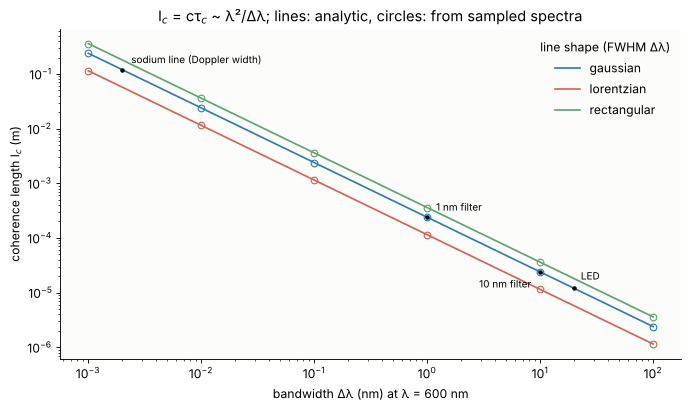

In [10]:
lam0 = 600e-9
dlams = np.logspace(-3, 2, 6)*1e-9
grids = {"gaussian": (3, 2001, 4, 801), "lorentzian": (100, 8001, 20, 1001),   # nu range, samples,
         "rectangular": (0.75, 2001, 60, 2001)}                               # tau range, samples (x 1/dnu)
shape_colours = {"gaussian": BLUE, "lorentzian": RED, "rectangular": GREEN}
fig, ax = plt.subplots(figsize=(8.5, 5), layout="constrained")
for shape, col in shape_colours.items():
    lc_num = []
    for dl in dlams:
        dnu = C_LIGHT*dl/lam0**2
        nu_max, n_nu, tau_max, n_tau = grids[shape]
        nu = np.linspace(-nu_max*dnu, nu_max*dnu, n_nu)
        S = coherence.line_spectrum(nu, dnu, shape)
        tau = np.linspace(0, tau_max/dnu, n_tau)
        lc_num.append(2*C_LIGHT*coherence.coherence_time(tau, coherence.degree_of_coherence(nu, S, tau)))
    dl_c = np.logspace(-3, 2, 100)*1e-9
    ax.loglog(dl_c*1e9, C_LIGHT*coherence.coherence_time_analytic(C_LIGHT*dl_c/lam0**2, shape), color=col,
              label=shape)
    ax.loglog(dlams*1e9, lc_num, "o", color=col, mfc="none")
for text, dl, off in [("LED", 20, (6, 8)), ("10 nm filter", 10, (-8, -14)), ("1 nm filter", 1, (8, 6)),
                      ("sodium line (Doppler width)", 0.002, (8, 6))]:
    ax.plot(dl, 0.664*lam0**2/(dl*1e-9), ".", color="k")
    ax.annotate(text, (dl, 0.664*lam0**2/(dl*1e-9)), xytext=off, textcoords="offset points",
                fontsize=9, ha="left" if off[0] > 0 else "right")
ax.set_xlabel("bandwidth Δλ (nm) at λ = 600 nm"); ax.set_ylabel("coherence length l$_c$ (m)")
ax.legend(frameon=False, title="line shape (FWHM Δλ)")
ax.set_title("l$_c$ = cτ$_c$ ~ λ²/Δλ; lines: analytic, circles: from sampled spectra")

The red supergiant's starlight in Michelson's eyepiece spanned some 200 nm,
so the two arms had to be equal to about a micron. In a Fourier transform
spectrometer the same relation is used the other way round: the spectrum is
the Fourier transform of the interferogram, and a scan over the path
difference $L$ resolves $\delta\tilde\nu = 1/L$ in wavenumbers. The sodium
doublet (17.2 cm⁻¹ apart) is resolved with a scan over 2 mm:

peaks of the recovered spectrum: 588.987 nm and 589.594 nm, ratio 0.50


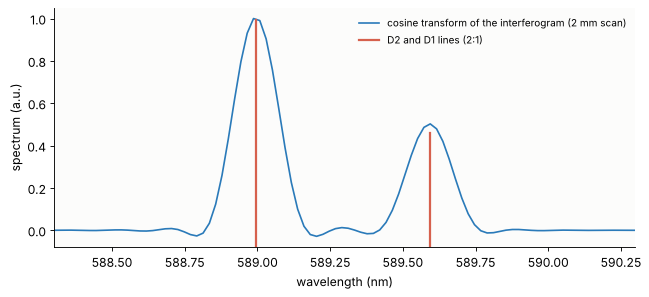

In [11]:
lam, S_lam, _ = sources["sodium doublet"]
keep = S_lam > 1e-9*S_lam.max()
nu = C_LIGHT/lam[keep]
w = S_lam[keep]*lam[keep]**2/C_LIGHT*np.abs(np.gradient(nu))
opd = np.arange(0, 2e-3, 0.125e-6)                 # one-sided scan, lambda/4.7 steps
I = michelson(opd, nu, w) - 1
spec = np.fft.rfft(I*np.hanning(2*len(opd))[len(opd):], n=8*len(opd)).real[1:]   # cosine transform
sigma = np.fft.rfftfreq(8*len(opd), opd[1])[1:]/100      # wavenumber in 1/cm
lam_fts = 1e7/sigma                                      # nm
win = (lam_fts > 588) & (lam_fts < 591)
lam_w, spec_w = lam_fts[win], spec[win]
peaks = [lam_w[(lam_w > a) & (lam_w < b)][np.argmax(spec_w[(lam_w > a) & (lam_w < b)])]
         for a, b in [(588.7, 589.3), (589.3, 589.9)]]
print("peaks of the recovered spectrum: {:.3f} nm and {:.3f} nm, ratio {:.2f}".format(
    *peaks, spec_w[lam_w == peaks[1]][0]/spec_w[lam_w == peaks[0]][0]))
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
ax.plot(lam_w, spec_w/spec_w.max(), color=BLUE, label="cosine transform of the interferogram (2 mm scan)")
for l0, a0 in [(588.995, 1), (589.592, 0.5)]:
    ax.axvline(l0, ymax=a0*0.95, color=RED, lw=2)
ax.set_xlim(588.3, 590.3); ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("spectrum (a.u.)")
ax.plot([], [], color=RED, lw=2, label="D2 and D1 lines (2:1)")
ax.legend(frameon=False, fontsize=9)

## 5. Hanbury Brown and Twiss: correlating intensities

In the 1950s Hanbury Brown and Twiss asked whether the coherence of
starlight could be measured without bringing the fields together. For
**chaotic (thermal) light** the field is a circular complex Gaussian random
process, the sum of very many independent emitters. For such fields the
fourth moment factorizes, and

$$\langle I_1I_2\rangle = \langle I_1\rangle\langle I_2\rangle
  \left(1 + |\mu_{12}|^2\right),\qquad
  g^{(2)}(\tau) = 1 + |g^{(1)}(\tau)|^2$$

(the Siegert relation): the *intensity fluctuations* at two points, or two
times, are correlated as $|\mu_{12}|^2$. The light of a single-mode laser
well above threshold has a constant amplitude and only a diffusing phase:
its $g^{(1)}$ decays the same way, but $g^{(2)} = 1$.

`coherence.chaotic_light()` filters complex white noise to a Gaussian line
of width $\Delta\nu$; the laser below has a Lorentzian line from phase
diffusion. Time is in units of $1/\Delta\nu$.

g2(0): thermal 2.000, laser 1.000;  max |g2 - 1 - |g1|^2| (thermal) = 0.007


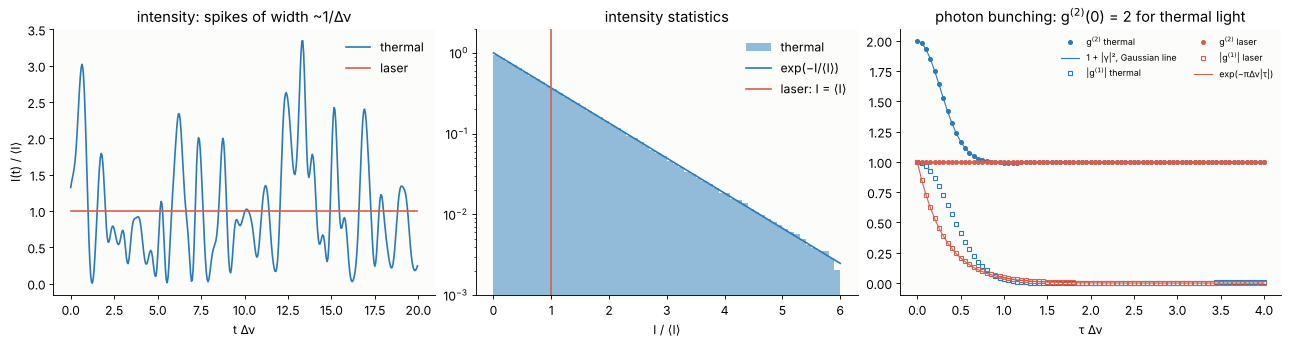

In [12]:
dt, n_t = 0.05, 2**16                         # time in units of 1/delta_nu
u_th = coherence.chaotic_light(n_t, dt, 1.0, "gaussian", rng, size=16)
phase = np.cumsum(np.sqrt(2*np.pi*1.0*dt)*rng.standard_normal((16, n_t)), axis=1)
u_las = np.exp(1j*phase)                      # Lorentzian line, FWHM 1
lags = np.arange(81)*dt

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), layout="constrained")
tt = np.arange(400)*dt
ax[0].plot(tt, np.abs(u_th[0, :400])**2, color=BLUE, label="thermal")
ax[0].plot(tt, np.abs(u_las[0, :400])**2, color=RED, label="laser")
ax[0].set_xlabel("t Δν"); ax[0].set_ylabel("I(t) / ⟨I⟩"); ax[0].legend(frameon=False)
ax[0].set_title("intensity: spikes of width ~1/Δν")
bins = np.linspace(0, 6, 61)
ax[1].hist(np.abs(u_th.ravel())**2, bins=bins, density=True, color=BLUE, alpha=0.5, label="thermal")
ax[1].plot(bins, np.exp(-bins), color=BLUE, label="exp(−I/⟨I⟩)")
ax[1].axvline(1, color=RED, label="laser: I = ⟨I⟩")
ax[1].set_yscale("log"); ax[1].set_ylim(1e-3, 2); ax[1].set_xlabel("I / ⟨I⟩")
ax[1].legend(frameon=False); ax[1].set_title("intensity statistics")
g1_th, g2_th = coherence.g1(u_th, 80), coherence.g2(np.abs(u_th)**2, 80)
g1_las, g2_las = coherence.g1(u_las, 80), coherence.g2(np.abs(u_las)**2, 80)
ax[2].plot(lags, g2_th, "o", ms=3.5, color=BLUE, label="g$^{(2)}$ thermal")
ax[2].plot(lags, 1 + coherence.line_coherence(lags, 1.0)**2, color=BLUE, lw=1,
           label="1 + |γ|², Gaussian line")
ax[2].plot(lags, np.abs(g1_th), "s", ms=3, color=BLUE, mfc="none", label="|g$^{(1)}$| thermal")
ax[2].plot(lags, g2_las, "o", ms=3.5, color=RED, label="g$^{(2)}$ laser")
ax[2].plot(lags, np.abs(g1_las), "s", ms=3, color=RED, mfc="none", label="|g$^{(1)}$| laser")
ax[2].plot(lags, coherence.line_coherence(lags, 1.0, "lorentzian"), color=RED, lw=1, label="exp(−πΔν|τ|)")
ax[2].set_xlabel("τ Δν"); ax[2].legend(frameon=False, fontsize=8, ncol=2)
ax[2].set_title("photon bunching: g$^{(2)}$(0) = 2 for thermal light")
print("g2(0): thermal {:.3f}, laser {:.3f};  max |g2 - 1 - |g1|^2| (thermal) = {:.3f}".format(
    g2_th[0], g2_las[0], np.max(np.abs(g2_th - 1 - np.abs(g1_th)**2))))

**Spatial intensity correlations.** The 2000 speckle realizations of
section 2 are the field of the disk at as many instants. Correlating their *intensities*
at a point $\mathbf r$ with those at the centre gives
$\langle\Delta I(\mathbf r)\Delta I(0)\rangle/\langle I\rangle^2 = |\mu|^2$,
the van Cittert–Zernike result squared: the phase of $\mu$ is lost, its
modulus measured. Now add the atmosphere as random pistons $\delta_1$,
$\delta_2$ (rms 1 rad each) on the fields at the two points, new in every
instant. The field correlation that an amplitude interferometer measures
drops by $e^{-\sigma^2} = 0.37$. The intensities do not see the phases at all.

rms |c - |mu_VCZ|^2| along the cut = 0.032


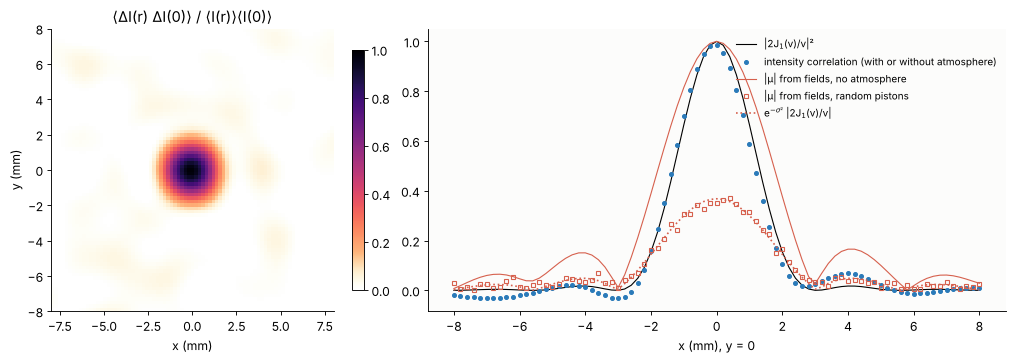

In [13]:
I_disk = np.abs(U_disk)**2
c_map = coherence.intensity_correlation(I_disk, I_disk[:, 40:41, 40:41]*np.ones_like(I_disk), axis=0)
d1 = rng.standard_normal((N_REAL, 81))
d2 = rng.standard_normal((N_REAL, 1))
U_atm = U_disk[:, 40, :]*np.exp(1j*d1)
U0_atm = U_disk[:, 40, 40:41]*np.exp(1j*d2)
mu_atm = np.mean(U_atm*np.conj(U0_atm), axis=0)/np.sqrt(np.mean(np.abs(U_atm)**2, 0)*np.mean(np.abs(U0_atm)**2))
mu_free = mu_from_realizations(U_disk)[40]
mu_th = coherence.uniform_disk_visibility(x_obs, 2*A2/Z2, WL2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), layout="constrained", gridspec_kw={"width_ratios": [1, 1.6]})
im = ax[0].imshow(c_map, extent=extent(x_obs, scale=1e3), cmap=LIGHT, vmin=0, vmax=1)
ax[0].set_title("⟨ΔI(r) ΔI(0)⟩ / ⟨I(r)⟩⟨I(0)⟩")
ax[0].set_xlabel("x (mm)"); ax[0].set_ylabel("y (mm)")
fig.colorbar(im, ax=ax[0], shrink=0.85)
ax[1].plot(x_obs*1e3, mu_th**2, color="k", lw=1, label="|2J$_1$(v)/v|²")
ax[1].plot(x_obs*1e3, c_map[40], "o", ms=3.5, color=BLUE, label="intensity correlation (with or without atmosphere)")
ax[1].plot(x_obs*1e3, np.abs(mu_free), color=RED, lw=1, label="|μ| from fields, no atmosphere")
ax[1].plot(x_obs*1e3, np.abs(mu_atm), "s", ms=3, color=RED, mfc="none", label="|μ| from fields, random pistons")
ax[1].plot(x_obs*1e3, np.exp(-1.0)*np.abs(mu_th), ":", color=RED, label="e$^{-σ²}$ |2J$_1$(v)/v|")
ax[1].set_xlabel("x (mm), y = 0"); ax[1].legend(frameon=False, fontsize=9)
print("rms |c - |mu_VCZ|^2| along the cut = {:.3f}".format(np.sqrt(np.mean((c_map[40] - mu_th**2)**2))))

**The price: slow detectors.** Optical bandwidths are $10^{13}$ to
$10^{14}$ Hz, detectors and correlators at Narrabri had about 60 MHz. A
detector averaging over $T \gg \tau_c$ sees intensity fluctuations reduced
by $\tau_c/T$: the correlation becomes

$$c(T) = |\mu_{12}|^2\,\frac{2}{T}\int_0^T\left(1 - \frac{\tau}{T}\right)|\gamma(\tau)|^2d\tau
  \;\to\; |\mu_{12}|^2\,\frac{\tau_c}{T},$$

some $10^{-5}$ in practice, which is why the measurements took hours of
photon noise averaging with large collectors. In return, the path
difference between the telescopes only needs to be good to $cT$, a fraction
of a metre instead of a micron, and the atmosphere's phases do not matter.
Below, chaotic light with $|\mu_{12}| = 1$ is averaged over windows of $T$
before correlating.

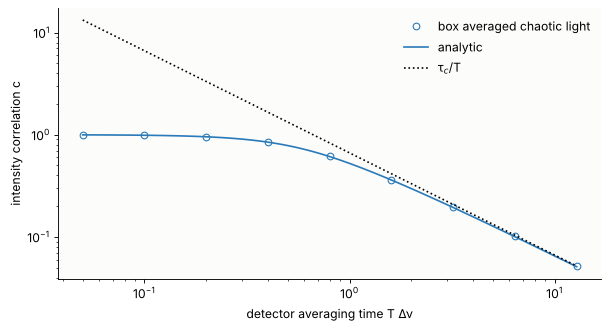

In [14]:
u_a = coherence.chaotic_light(2**20, dt, 1.0, "gaussian", rng, size=4)
I_a = np.abs(u_a)**2
T_list = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256])          # samples
c_T = []
for m in T_list:
    Ib = I_a[:, :I_a.shape[1]//m*m].reshape(4, -1, m).mean(axis=2)
    c_T.append(np.mean([coherence.intensity_correlation(Ib[j], Ib[j]) for j in range(4)]))
T_c = np.logspace(np.log10(dt), np.log10(256*dt), 100)
c_th = [detector_correlation(T) for T in T_c]
tau_c = coherence.coherence_time_analytic(1.0)
fig, ax = plt.subplots(figsize=(7.5, 4), layout="constrained")
ax.loglog(T_list*dt, c_T, "o", color=BLUE, mfc="none", label="box averaged chaotic light")
ax.loglog(T_c, c_th, color=BLUE, label="analytic")
ax.loglog(T_c, tau_c/T_c, ":", color="k", label="τ$_c$/T")
ax.set_xlabel("detector averaging time T Δν"); ax.set_ylabel("intensity correlation c")
ax.legend(frameon=False)

**Sirius.** Hanbury Brown and Twiss resolved Sirius with two searchlight
mirrors in 1956; the Narrabri intensity interferometer (two 6.5 m mosaic
reflectors on a circular track, 443 nm) later measured 32 stars, among them
Sirius with a limb darkened diameter close to 6 mas. Below, a star of
5.9 mas with weak limb darkening ($u = 0.4$) is observed at eight baselines:
pairs of chaotic time series with the degree of coherence of the star
(`coherence.correlated_chaotic_pair()`), averaged by a detector with
$T = 4\tau_c$, correlated, and normalized by the correlation at zero
baseline, as at Narrabri. Fitting $|\mu(B)|^2$ gives the diameter.

correlation at zero baseline with T = 3.2/delta_nu: 0.192 (analytic 0.194)


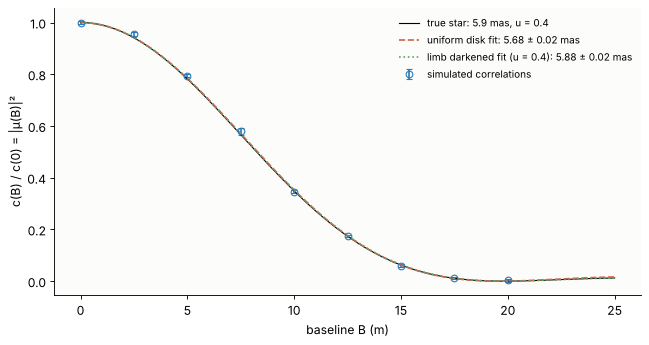

In [15]:
WL_N = 443e-9
THETA_SIR, U_SIR = 5.9*MAS, 0.4
B_n = np.array([0.0, 2.5, 5, 7.5, 10, 12.5, 15, 17.5, 20])
m_avg, n_rep = 64, 6                 # T = 64 samples = 3.2/delta_nu (about 4.8 tau_c)


def measure(B):
    mu = coherence.limb_darkened_disk_visibility(B, THETA_SIR, WL_N, U_SIR)
    cs = []
    for _ in range(n_rep):
        u1, u2 = coherence.correlated_chaotic_pair(2**18, dt, 1.0, mu, rng=rng)
        I1b = (np.abs(u1)**2).reshape(-1, m_avg).mean(1)
        I2b = (np.abs(u2)**2).reshape(-1, m_avg).mean(1)
        cs.append(coherence.intensity_correlation(I1b, I2b))
    return np.mean(cs), np.std(cs)/np.sqrt(n_rep)


meas = np.array([measure(B) for B in B_n])
c0 = meas[0, 0]
c_norm, c_err = meas[:, 0]/c0, meas[:, 1]/c0
fit_ud, cov_ud = curve_fit(lambda B, th: coherence.uniform_disk_visibility(B, th*MAS, WL_N)**2,
                           B_n, c_norm, p0=[5], sigma=np.maximum(c_err, 1e-3))
fit_ld, cov_ld = curve_fit(lambda B, th: coherence.limb_darkened_disk_visibility(B, th*MAS, WL_N, U_SIR)**2,
                           B_n, c_norm, p0=[5], sigma=np.maximum(c_err, 1e-3))
B_c = np.linspace(0, 25, 300)
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.errorbar(B_n, c_norm, c_err, fmt="o", color=BLUE, mfc="none", capsize=3, label="simulated correlations")
ax.plot(B_c, coherence.limb_darkened_disk_visibility(B_c, THETA_SIR, WL_N, U_SIR)**2, color="k", lw=1,
        label="true star: 5.9 mas, u = 0.4")
ax.plot(B_c, coherence.uniform_disk_visibility(B_c, fit_ud[0]*MAS, WL_N)**2, "--", color=RED,
        label="uniform disk fit: {:.2f} ± {:.2f} mas".format(fit_ud[0], np.sqrt(cov_ud[0, 0])))
ax.plot(B_c, coherence.limb_darkened_disk_visibility(B_c, fit_ld[0]*MAS, WL_N, U_SIR)**2, ":", color=GREEN,
        label="limb darkened fit (u = 0.4): {:.2f} ± {:.2f} mas".format(fit_ld[0], np.sqrt(cov_ld[0, 0])))
ax.set_xlabel("baseline B (m)"); ax.set_ylabel("c(B) / c(0) = |μ(B)|²")
ax.legend(frameon=False, fontsize=9)
print("correlation at zero baseline with T = {:.1f}/delta_nu: {:.3f} (analytic {:.3f})".format(
    m_avg*dt, c0, detector_correlation(m_avg*dt)))

The limb darkened fit recovers the input diameter within its error bars;
the uniform disk fit gives a slightly smaller star, as for Betelgeuse in
section 3. Because only $|\mu|^2$ is measured, an intensity interferometer
cannot tell a binary's position angle from its mirror image, and the
signal is tiny; but it works with crude light buckets, baselines of
hundreds of metres and any seeing. Its quantum interpretation, photon
bunching (Purcell 1956), was controversial at first and started quantum
optics. Today intensity interferometry is revived with Cherenkov
telescope arrays and fast single-photon detectors.

## Summary

- The fringe visibility of two points is the modulus of their degree of
  coherence; its phase shows as a fringe shift, a negative $\mu$ as
  reversed fringes. `coherence.fit_fringes()` measures both.
- **Van Cittert–Zernike:** an incoherent source makes $\mu$ equal to the
  normalized Fourier transform of its intensity
  (`coherence.mutual_intensity_vcz()`): $2J_1(v)/v$ for a disk,
  `uniform_disk_visibility()`, with a first zero at $1.22\,\lambda/\theta$,
  `limb_darkened_disk_visibility()` and `binary_visibility()` for stars.
  Incoherent sums of coherent propagations (point by point in a Young
  experiment, or random realizations of the source with
  `incoherent_source_realization()`) reproduce it to their sampling and
  statistical errors.
- **Michelson's stellar interferometer** separates fringe spacing (inner
  mirrors) from baseline (outer mirrors). The fringes of a 47 mas disk
  vanish at 3.07 m, as for Betelgeuse in 1920. A uniform disk fitted to a
  limb darkened star comes out too small. Random pistons from the
  atmosphere reduce the long exposure visibility by $e^{-\sigma^2/2}$.
- **Temporal coherence:** the visibility against path difference is the
  Fourier transform of the spectrum (`degree_of_coherence()`); the
  coherence length is $0.664$, $0.318$ or $1\times\lambda^2/\Delta\lambda$
  for Gaussian, Lorentzian and rectangular lines
  (`coherence_time_analytic()`, `coherence_time()`). Two lines beat; the
  inverse transform of an interferogram is the spectrum.
- **Hanbury Brown–Twiss:** chaotic light (`chaotic_light()`) has
  exponential intensity statistics and $g^{(2)} = 1 + |g^{(1)}|^2$
  (`g1()`, `g2()`), a laser $g^{(2)} = 1$. Intensity correlations
  (`intensity_correlation()`) measure $|\mu_{12}|^2$, unaffected by
  atmospheric phases, but reduced by $\tau_c/T$ for slow detectors.
  `correlated_chaotic_pair()` simulates a stellar intensity interferometer.

## References

- P. H. van Cittert, "Die wahrscheinliche Schwingungsverteilung in einer von einer Lichtquelle direkt oder mittels einer Linse beleuchteten Ebene", Physica 1, 201-210 (1934).
- F. Zernike, "The concept of degree of coherence and its application to optical problems", Physica 5, 785-795 (1938).
- A. A. Michelson, "On the application of interference methods to astronomical measurements", Astrophys. J. 51, 257-262 (1920).
- A. A. Michelson and F. G. Pease, "Measurement of the diameter of alpha Orionis with the interferometer", Astrophys. J. 53, 249-259 (1921).
- R. Hanbury Brown and R. Q. Twiss, "Correlation between photons in two coherent beams of light", Nature 177, 27-29 (1956).
- R. Hanbury Brown and R. Q. Twiss, "A test of a new type of stellar interferometer on Sirius", Nature 178, 1046-1048 (1956).
- E. M. Purcell, "The question of correlation between photons in coherent light rays", Nature 178, 1449-1450 (1956).
- R. Hanbury Brown, J. Davis and L. R. Allen, "The angular diameters of 32 stars", Mon. Not. R. Astron. Soc. 167, 121-136 (1974).
- M. Born and E. Wolf, Principles of Optics, 7th ed., Cambridge University Press (1999), chapter 10.
- L. Mandel and E. Wolf, Optical Coherence and Quantum Optics, Cambridge University Press (1995), chapters 4 and 9.
- J. W. Goodman, Statistical Optics, 2nd ed., Wiley (2015), chapters 5 and 6.

In [16]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 63 s
